In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import transforms, datasets
from torch.utils.data import DataLoader, random_split
import json
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import time
import os

In [19]:
# 检查CUDA可用性
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"使用设备: {device}")

使用设备: cuda


In [20]:
# 创建结果目录
os.makedirs('results', exist_ok=True)

In [21]:
# 针对1600x350尺寸的预处理
transform = transforms.Compose([
    transforms.Resize((350, 1600)),  # 保持原始宽高比
    transforms.CenterCrop((320, 1536)),  # 中心裁剪以去除边缘噪点
    transforms.Resize((80, 384)),  # 按比例缩小到1/4
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

In [22]:
# 加载数据集
dataset = datasets.ImageFolder('D:\STUDY\internship\code_internship\dataset\images', transform=transform)

<>:2: SyntaxWarning: invalid escape sequence '\S'
<>:2: SyntaxWarning: invalid escape sequence '\S'
C:\Users\user\AppData\Local\Temp\ipykernel_7236\707649435.py:2: SyntaxWarning: invalid escape sequence '\S'
  dataset = datasets.ImageFolder('D:\STUDY\internship\code_internship\dataset\images', transform=transform)


In [23]:
# 保存类别映射
with open('results/class_indices.json', 'w') as f:
    json.dump(dataset.class_to_idx, f)

In [24]:
# 划分训练集和验证集
train_size = int(0.8 * len(dataset))
val_size = len(dataset) - train_size
train_dataset, val_dataset = random_split(dataset, [train_size, val_size])
# 创建数据加载器
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=4)
val_loader = DataLoader(val_dataset, batch_size=16, num_workers=4)

In [25]:
# special CNN model for 1600x350 images
class AspectAwareCNN(nn.Module):
    def __init__(self, num_classes=5):
        super(AspectAwareCNN, self).__init__()
        # input size: [3, 80, 384]
        self.conv_layers = nn.Sequential(
            # conv1
            nn.Conv2d(3, 32, kernel_size=(3, 7), padding=(1, 3)),  # wide kernel to handle aspect ratio
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d((2, 4)),  # output: [32, 40, 96]
            
            # conv2
            nn.Conv2d(32, 64, kernel_size=(3, 7), padding=(1, 3)),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d((2, 4)),  # output: [64, 20, 24]
            
            # conv3
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d((2, 2)),  # output: [128, 10, 12]
        )
        
        # selfadaptive pooling to handle variable input sizes
        self.adaptive_pool = nn.AdaptiveAvgPool2d((5, 6))
        
        self.fc_layers = nn.Sequential(
            nn.Linear(128 * 5 * 6, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )
    
    def forward(self, x):
        x = self.conv_layers(x)
        x = self.adaptive_pool(x)
        x = torch.flatten(x, 1)
        return self.fc_layers(x)

In [26]:
# 初始化模型
model = AspectAwareCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.00002)

In [27]:
# 训练函数
def train(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0
    
    for inputs, labels in loader:
        inputs, labels = inputs.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * inputs.size(0)
        _, predicted = torch.max(outputs, 1)
        correct += (predicted == labels).sum().item()
        total += labels.size(0)
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

# 验证函数
def validate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for inputs, labels in loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            
            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
    
    epoch_loss = running_loss / total
    epoch_acc = correct / total
    return epoch_loss, epoch_acc

In [28]:
# 记录训练过程的指标
train_losses = []
train_accs = []
val_losses = []
val_accs = []
best_acc = 0.0

In [29]:
# 训练循环
num_epochs = 20
start_time = time.time()

print(f"{'Epoch':^7} | {'Train Loss':^12} | {'Train Acc':^10} | {'Val Loss':^10} | {'Val Acc':^9} | {'Time':^9}")
print("-" * 70)

for epoch in range(num_epochs):
    epoch_start = time.time()
    
    # 训练并验证
    train_loss, train_acc = train(model, train_loader, optimizer, criterion)
    val_loss, val_acc = validate(model, val_loader, criterion)
    
    # 记录指标
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    
    
    epoch_time = time.time() - epoch_start
    
    # 打印进度
    print(f"{epoch+1:^7} | {train_loss:^12.4f} | {train_acc:^10.4f} | "
          f"{val_loss:^10.4f} | {val_acc:^9.4f} | {epoch_time:^8.2f}s")

total_time = time.time() - start_time
print(f"\nfinish: {total_time/60:.2f}minutes")
print(f"the best accuracy: {best_acc:.4f}")

 Epoch  |  Train Loss  | Train Acc  |  Val Loss  |  Val Acc  |   Time   
----------------------------------------------------------------------
   1    |    1.4514    |   0.4025   |   1.3144   |  0.6400   |  18.12  s
   2    |    1.1317    |   0.6250   |   0.9224   |  0.6600   |  18.17  s
   3    |    0.9011    |   0.6775   |   0.7368   |  0.7700   |  18.19  s
   4    |    0.7805    |   0.7113   |   0.6317   |  0.7800   |  18.28  s
   5    |    0.6737    |   0.7325   |   0.5617   |  0.8100   |  18.15  s
   6    |    0.6269    |   0.7600   |   0.5050   |  0.8250   |  19.74  s
   7    |    0.5814    |   0.7800   |   0.4753   |  0.8700   |  18.76  s
   8    |    0.5566    |   0.7788   |   0.4576   |  0.8300   |  18.48  s
   9    |    0.5150    |   0.7963   |   0.4315   |  0.8400   |  18.38  s
  10    |    0.4818    |   0.8000   |   0.4182   |  0.8250   |  18.40  s
  11    |    0.4805    |   0.7987   |   0.4232   |  0.8050   |  18.37  s
  12    |    0.4830    |   0.7963   |   0.3979   |  0

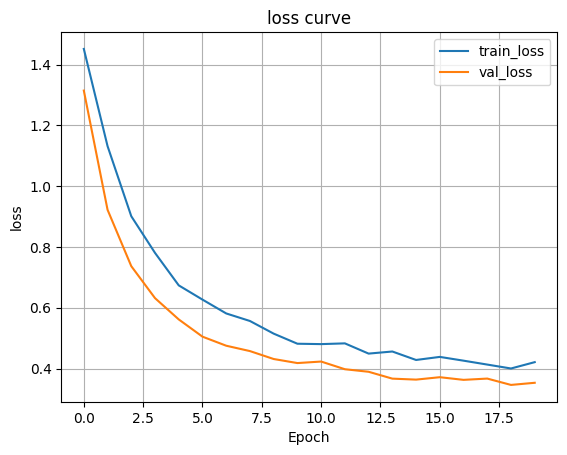

In [30]:
# 绘制训练曲线

# 损失曲线
plt.plot(train_losses, label='train_loss')
plt.plot(val_losses, label='val_loss')
plt.title('loss curve')
plt.xlabel('Epoch')
plt.ylabel('loss')
plt.legend()
plt.grid(True)


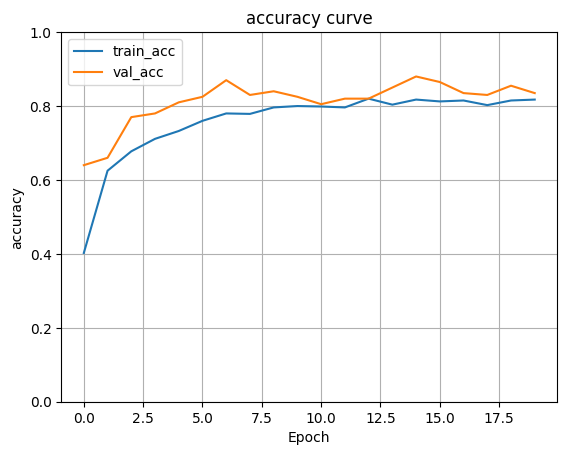

In [31]:

# 准确率曲线
plt.plot(train_accs, label='train_acc')
plt.plot(val_accs, label='val_acc')
plt.title('accuracy curve')
plt.xlabel('Epoch')
plt.ylabel('accuracy')
plt.ylim(0, 1)  # 设置y轴范围0-1
plt.legend()
plt.grid(True)

Text(95.72222222222221, 0.5, 'real labels')

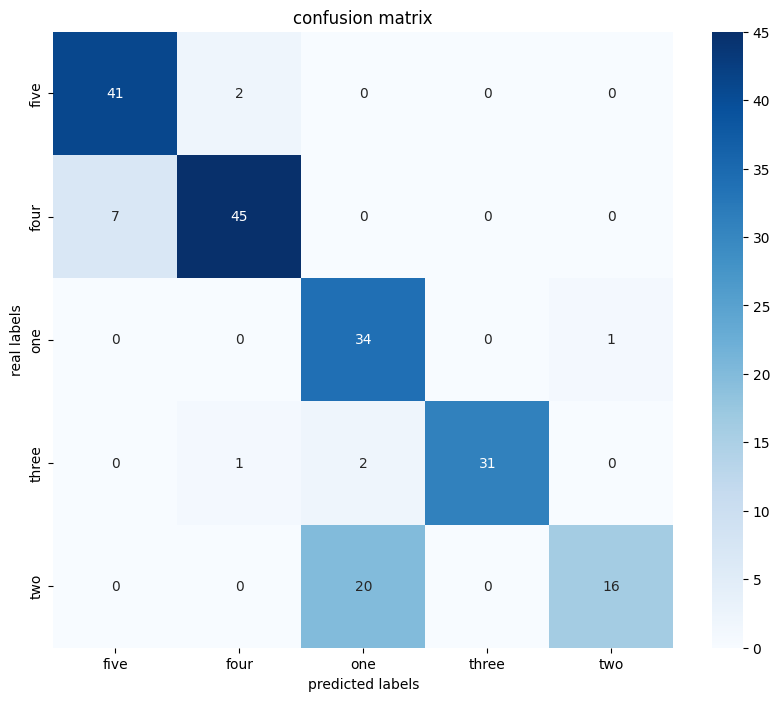

In [32]:
# 绘制混淆矩阵（额外评估）
from sklearn.metrics import confusion_matrix
import seaborn as sns

# 收集所有预测
all_labels = []
all_preds = []

model.eval()
with torch.no_grad():
    for inputs, labels in val_loader:
        inputs = inputs.to(device)
        outputs = model(inputs)
        _, preds = torch.max(outputs, 1)
        
        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(preds.cpu().numpy())

# 生成混淆矩阵
cm = confusion_matrix(all_labels, all_preds)

# 类别名称
class_names = list(dataset.class_to_idx.keys())

# 绘制混淆矩阵
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.title('confusion matrix')
plt.xlabel('predicted labels')
plt.ylabel('real labels')

In [33]:
# 预测函数示例
def predict_image(image_path):
    # 加载类别映射
    with open('results/class_indices.json') as f:
        class_mapping = json.load(f)
    idx_to_class = {v: k for k, v in class_mapping.items()}
    
    # 加载并预处理图像
    image = Image.open(image_path).convert('RGB')
    image_tensor = transform(image).unsqueeze(0).to(device)
    
    # 预测
    model.load_state_dict(torch.load('results/best_model.pth'))
    model.eval()
    with torch.no_grad():
        output = model(image_tensor)
        probabilities = torch.softmax(output, dim=1)[0] * 100
        _, predicted_idx = torch.max(output, 1)
        predicted_class = idx_to_class[predicted_idx.item()]
    
    # 打印每个类别的概率
    print("\n预测结果:")
    for i, class_name in enumerate(class_names):
        print(f"{class_name}: {probabilities[i]:.2f}%")
    
    return predicted_class

In [34]:
# 测试预测
test_image = r'D:\STUDY\internship\raw_data\100µm_10Hz_5N\Séquence images\im0031.tif'  # 替换为实际路径
print(f"\n测试图像预测结果: {predict_image(test_image)}")

C:\Users\user\AppData\Local\Temp\ipykernel_7236\172492948.py:13: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('results/best_model.pth'))


FileNotFoundError: [Errno 2] No such file or directory: 'results/best_model.pth'